<a href="https://colab.research.google.com/github/Mohamed-Qadar/Somali-News-Classification-Dataset/blob/main/Somali_News_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Somali News AI — Colab Notebook
**Mohamed Ibrahim Abdi — SNAIC AI Day 2026**

Classifies Somali news headlines into categories (Economy, Politics, Sports, World).
*Wuxuu u kala saaraa cinwaanada wararka Soomaaliga noocyo (Dhaqaale, Siyaasad, Isboorti, Caalam).*

Dataset: Somali News Classification Dataset (SNCD). Run the cells in order. / *Ku shaqee unugyada siday u kala horreeyaan.*

## 1 · Connect Google Drive — *Isku xir Google Drive*

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2 · Install libraries (Gradio) — *Rakib maktabadaha (Gradio)*

In [2]:
!pip install -q gradio scikit-learn pandas matplotlib

## 3 · Import libraries — *Soo deji maktabadaha*

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 4 · Load the dataset — *Soo raric xogta*
Upload the CSV to your Google Drive, then edit `DATA_PATH`. / *Soo geli CSV-ga Google Drive, kadib wax ka beddel `DATA_PATH`.*

Kaggle: kaggle.com/datasets/mohamedibrahimabdi/somali-news-classification-dataset-sncd

In [4]:
DATA_PATH = "/content/drive/MyDrive/Somali News Classification Dataset (SNCD) (1).csv"

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")   # utf-8-sig removes the BOM / saaraya BOM-ka hore
print("Loaded / La soo raray:", df.shape)
df.head()

Loaded / La soo raray: (20475, 4)


,text,label,source,url
0,BF oo maanta meel-mariyay miisaaniyadda qarank...,Politics,Caasimada,NaN
1,Faah-faahinta dil ka dhacay magaalada Gaalkacyo,Politics,Caasimada,NaN
2,Dowladda Mareykanka oo u yeertay safiirkeeda S...,Politics,Caasimada,NaN
3,Taiwan oo si adag ugu soo jawaabtay madaxweyne...,Politics,Caasimada,NaN
4,Golaha Mustaqbalka oo soo saaray bayaan cusub ...,Politics,Caasimada,NaN


## 5 · First look at the data — *Eegista hore ee xogta*

In [5]:
print("Rows x Columns / Safaf x Tiirar:", df.shape)
print("\nColumns / Tiirar:", list(df.columns))
print("\nData types / Noocyada xogta:")
print(df.dtypes)
print("\nSample rows / Safafyo tusaale ah:")
display(df.sample(5))

wl = df["text"].astype(str).str.split().str.len()
print("\nText length in words / Dherer qoraal (erayo)  min:%d  median:%d  mean:%.1f  max:%d"
      % (wl.min(), wl.median(), wl.mean(), wl.max()))

Rows x Columns / Safaf x Tiirar: (20475, 4)

Columns / Tiirar: ['text', 'label', 'source', 'url']

Data types / Noocyada xogta:
text      object
label     object
source    object
url       object
dtype: object

Sample rows / Safafyo tusaale ah:


,text,label,source,url
13235,Muxuu Modric Ka Yidhi Guuldaradii Kooxdiisa Ka...,Sports,Kooxda,https://kooxda.com/muxuu-modric-ka-yidhi-guuld...
10269,Madaxweynaha Ukraine oo hal shardi ku xiray wa...,World,Caasimada,NaN
3473,Somaliland oo qiratay in uu dhaqan-galay e-vis...,Politics,Caasimada,NaN
7181,Mareykanka oo Turkey uga digay inay marti-geli...,World,Caasimada,NaN
3928,Sawirro: Xasan Sheekh oo la kulmay amiirka Qat...,Politics,Caasimada,NaN



Text length in words / Dherer qoraal (erayo)  min:3  median:11  mean:11.4  max:215


In [6]:
# Calculate the total number of tokens (words) in the 'text' column
total_tokens = df['text'].astype(str).str.split().str.len().sum()
print(f"Total tokens (words) in the dataset: {total_tokens:,}")

Total tokens (words) in the dataset: 233,054


## 6 · Category distribution — *Qaybinta noocyada*

label
Politics    5255
World       5255
Sports      5255
Economy     4710
Name: count, dtype: int64

Percent / Boqolkiiba:
label
Politics    25.7
World       25.7
Sports      25.7
Economy     23.0
Name: count, dtype: float64


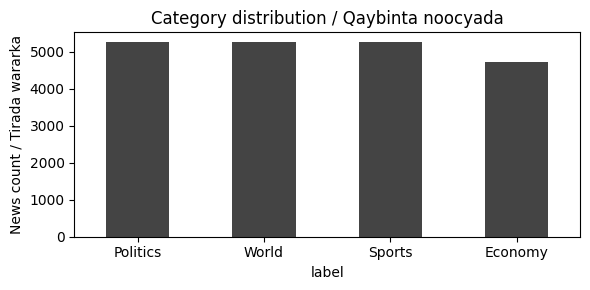

In [7]:
dist = df["label"].value_counts()
print(dist)
print("\nPercent / Boqolkiiba:")
print((dist / len(df) * 100).round(1))

plt.figure(figsize=(6,3))
dist.plot(kind="bar", color="#444444")
plt.title("Category distribution / Qaybinta noocyada"); plt.ylabel("News count / Tirada wararka")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 7 · Missing values — *Qiimayaal maqan*

In [8]:
print("Missing per column / Maqan tiir kasta:")
print(df.isna().sum())

empty = (df["text"].astype(str).str.strip() == "").sum()
print("\nEmpty text count / Tirada qoraalka madhan:", empty)

Missing per column / Maqan tiir kasta:
text          0
label         0
source        0
url       10510
dtype: int64

Empty text count / Tirada qoraalka madhan: 0


## 8 · Inspect labels — *Baadhista calaamadaha*

In [9]:
print("Unique labels / Calaamado gaar ah:", df["label"].unique())
print("Number of labels / Tirada calaamadaha:", df["label"].nunique())

print("\nFull-row duplicates / Safaf gabi isku mid:", df.duplicated().sum())
print("Duplicate text / Qoraal isku mid:", df.duplicated(subset=["text"]).sum())

conflict = df.groupby("text")["label"].nunique()
print("Conflicting text (same text > 1 label) / Qoraal is-burinaya:", (conflict > 1).sum())

Unique labels / Calaamado gaar ah: ['Politics' 'World' 'Sports' 'Economy']
Number of labels / Tirada calaamadaha: 4

Full-row duplicates / Safaf gabi isku mid: 6483
Duplicate text / Qoraal isku mid: 6671
Conflicting text (same text > 1 label) / Qoraal is-burinaya: 188


## 9 · Cleaning (leakage-safe) — *Nadiifinta (xog-dhicis la'aan)*

In [10]:
df_clean = df[["text", "label"]].copy()
df_clean["text"] = df_clean["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df_clean = df_clean[df_clean["text"].str.len() > 0]

# remove conflicting text / saar qoraalka is-burinaya
conf = df_clean.groupby("text")["label"].nunique()
bad = set(conf[conf > 1].index)
df_clean = df_clean[~df_clean["text"].isin(bad)]

# remove duplicates BEFORE the split (prevents leakage) / saar isku-celinta KA HOR qaybinta
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["text"])

print("Before / Ka hor:", df.shape[0], "-> After / Ka dib:", df_clean.shape[0])
print("Removed conflicting / La saaray is-burinaya:", len(bad),
      "| Removed duplicates / La saaray isku-celin:", before - len(df_clean))
print("\nClean distribution / Qaybinta nadiif ah:")
print(df_clean["label"].value_counts())

Before / Ka hor: 20475 -> After / Ka dib: 13616
Removed conflicting / La saaray is-burinaya: 188 | Removed duplicates / La saaray isku-celin: 2496

Clean distribution / Qaybinta nadiif ah:
label
Sports      5255
Economy     4710
World       1829
Politics    1822
Name: count, dtype: int64


## 10 · Features + train & compare 3 models — *Astaamo + tababar oo isbarbardhig 3 model*

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

X = df_clean["text"].astype(str)
y = df_clean["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Train / Tababar:", len(X_train), " Test / Imtixaan:", len(X_test))

def features():
    # word n-grams (topic) + char n-grams (Somali morphology)
    # erayo n-gram (mawduuc) + xaraf n-gram (naxwaha Soomaaliga)
    return FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word",    ngram_range=(1,2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), min_df=2, sublinear_tf=True)),
    ])

models = {
    "Naive Bayes":         ComplementNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=5, class_weight="balanced"),
    "Linear SVM":          LinearSVC(C=1.0, class_weight="balanced"),
}
for name, clf in models.items():
    pipe = Pipeline([("features", features()), ("clf", clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"{name:<20} accuracy={accuracy_score(y_test,pred):.4f}  "
          f"macro-F1={f1_score(y_test,pred,average='macro'):.4f}")

Train / Tababar: 10892  Test / Imtixaan: 2724
Naive Bayes          accuracy=0.9299  macro-F1=0.8919
Logistic Regression  accuracy=0.9629  macro-F1=0.9425
Linear SVM           accuracy=0.9673  macro-F1=0.9485


## 11 · Best model + report + confusion matrix — *Modelka ugu wanaagsan + warbixin*

              precision    recall  f1-score   support

     Economy      0.975     0.968     0.972       942
    Politics      0.899     0.877     0.888       365
      Sports      0.998     1.000     0.999      1051
       World      0.895     0.929     0.912       366

    accuracy                          0.963      2724
   macro avg      0.942     0.943     0.942      2724
weighted avg      0.963     0.963     0.963      2724



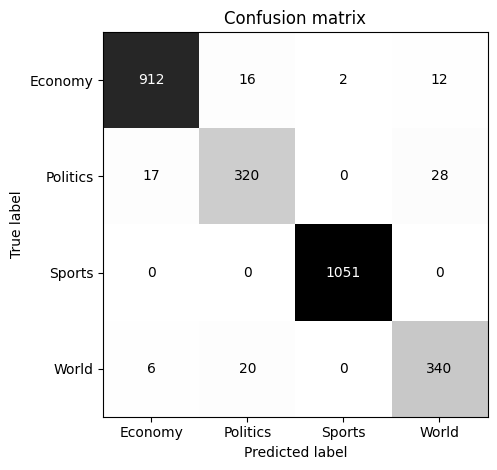

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model = Pipeline([("features", features()),
                  ("clf", LogisticRegression(max_iter=2000, C=5, class_weight="balanced"))]).fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=3))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Greys", colorbar=False)
plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

## 12 · Live test with Gradio — *Tijaabo toos ah oo Gradio ah*

In [13]:
import gradio as gr

def classify(text):
    if not text or not text.strip():
        return {}
    proba = model.predict_proba([text])[0]
    return {cls: float(p) for cls, p in zip(model.classes_, proba)}

demo = gr.Interface(
    fn=classify,
    inputs=gr.Textbox(lines=2, label="Write a Somali headline / Cinwaan war Soomaali ah qor"),
    outputs=gr.Label(num_top_classes=4, label="Prediction / Saadaasha"),
    title="Somali News AI",
    description="Type a Somali news headline and the model predicts the category (Economy, Politics, Sports, World). / Cinwaan war Soomaali ah qor, modelku nooca ha kuu saaro.",
    examples=[
        ["Wasiirka Maaliyadda oo kormeer ku tagay dekedda Kismaayo"],
        ["Arsenal oo garoonka ku garaacay Chelsea kulankii Premier League"],
        ["Trump oo ku dhawaaqay heshiis xabad-joojin ah oo Israel iyo Iran dhex-mara"],
    ],
)
demo.launch(share=True)   # share=True -> public test link / link guud oo tijaabo

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f3ce3834d389c332b6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
